In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt

In [13]:
bk_file = "../data/bk_samplefrommvefit.dat"
BKinterpolator = dipole.BKDipole(bk_file)
init = [1.0, 0.8, 1.0, 1.0]
lbounds = [0.001, 0.1, 1/np.exp(1), 0.001]
ubounds = [10.0, 100.1, 100.0, 10.0]
y_array = np.linspace(0, 10, 5)
r = np.logspace(-3, 2, 50)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function

fit_params_array = np.ones((len(y_array), 4))
i = 0
for y in y_array:
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds)
    out = minimizer.fit_ls()
    fit_params= out.x
    fit_params_array[i, :] = fit_params
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params)
    i += 1

### y =  0.0
[ 0.07342806  1.07808593 13.85981828  0.94808284]
### y =  2.5
[0.15274861 1.54029476 0.36787944 0.63992591]
### y =  5.0
[0.77186402 0.8621838  0.4374939  1.1577028 ]
### y =  7.5
[1.35103882 0.83126437 0.36787945 1.15410984]
### y =  10.0
[1.56846712 0.96601556 0.36787947 0.93213618]


Text(0, 0.5, 'N(r,y)')

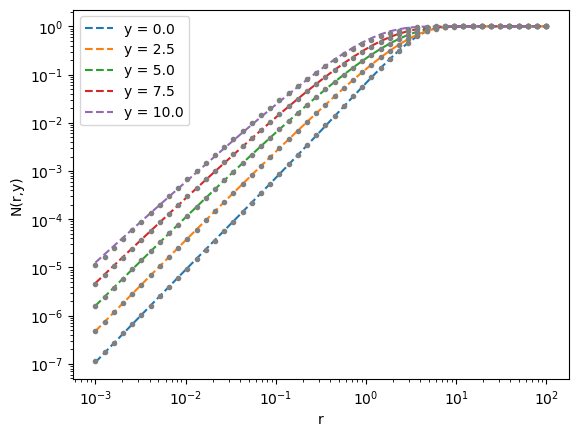

In [14]:
i = 0
for y in y_array:
    fit_params = fit_params_array[i, :]
    fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    plt.plot(r, np.exp(fit_func), '--', label='y = '+str(np.round(y,3)))
    plt.plot(r, np.exp(Nyr(y,r)), '.', color = 'gray')
    i += 1
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('N(r,y)')


## Get Fourier transform

In [15]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

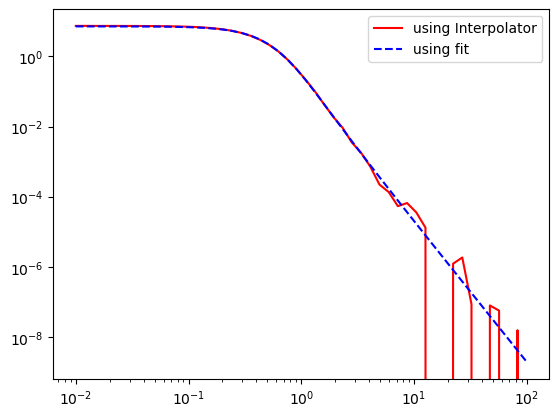

In [19]:
fit_params = fit_params_array[1]
k = np.logspace(-2, 2, 50)
Sk = S(2.5,k)
Sk2 = S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, Sk2, '--', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')